<a href="https://colab.research.google.com/github/JulTob/Modelling/blob/main/GLM/GLM_2_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

equipo	N	m_sin	disp_sin	p0_fraude	p_evento	p_baja	m_coste
equipo_07	260107	1.1	1.1	1	1.1	0.7	1.7	1.05	0.56


In [1]:

library(tidyverse)
library(dplyr)
library(ggplot2)
library(treemapify)

# Fuente de datos del equipo 07
repositorio <- "https://raw.githubusercontent.com/JulTob/Modelling/698dad06c4228ea79319fdba27647a0c61474703/GLM/"

cartera <- read_csv(
    paste0(repositorio, "cartera.csv"),
    show_col_types = FALSE
    )

# Comprobar que los datos son válidos
stopifnot(
    nrow(cartera) > 0,
    all(c("n_siniestros", "n_asistencia", "exposicion")    %in% names(cartera)),
    all(!is.na(cartera$exposicion)),
    all(cartera$exposicion > 0)
    )

glimpse(cartera)
summary(cartera$exposicion)

class(cartera)
is.data.frame(cartera)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


Rows: 3,062
Columns: 40
$ id_poliza           <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15,…
$ id_agencia          <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ id_region           <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ antiguedad          <dbl> 1.082, 6.687, 5.732, 1.397, 1.968, 3.159, 3.821, 7…
$ exposicion          <dbl> 0.1082, 0.6687, 0.5732, 0.1397, 0.1968, 0.3159, 0.…
$ edad_conductor      <dbl> 33, 44, 62, 25, 66, 25, 18, 44, 49, 36, 77, 36, 39…
$ edad_tramo          <chr> "25-35", "35-65", "35-65", "18-25", "65+", "18-25"…
$ antiguedad_carnet   <dbl> 7, 13, 36, 6, 36, 7, 0, 11, 30, 7, 49, 12, 16, 17,…
$ potencia_cv         <dbl> 85, 142, 118, 76, 55, 120, 143, 64, 113, 136, 141,…
$ cilindrada          <dbl> 1417, 2423, 1831, 1278, 824, 1816, 1730, 1006, 162…
$ antiguedad_vehiculo <dbl> 6, 12, 6, 9, 10, 6, 11, 10, 19, 4, 7, 12, 19, 4, 7…
$ valor_vehiculo      <dbl> 35790, 22089, 31528, 25948, 20714, 15821, 23040, 2…
$ densidad      

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.0100  0.2194  0.3768  0.4207  0.5934  0.9996 

[1] "spec_tbl_df" "tbl_df"      "tbl"         "data.frame"

[1] TRUE

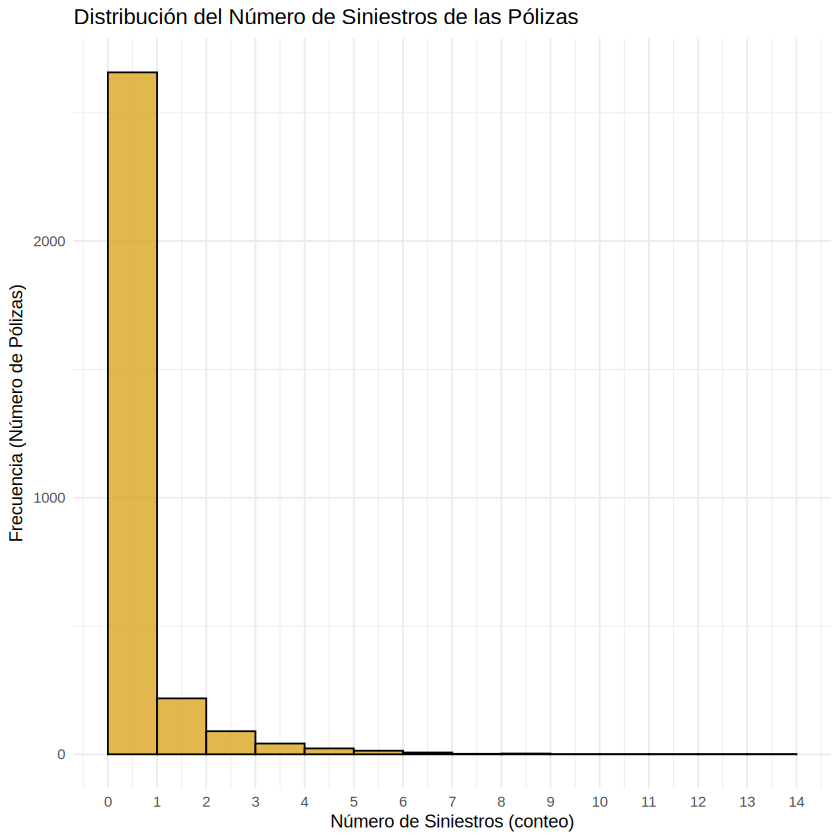

In [2]:

# Crear histograma de la variable antiguedad con cortes en enteros [0,1), [1,2), etc.
ggplot(cartera, aes(x = n_siniestros)) +
  geom_histogram(binwidth = 1, boundary = 0, fill = "goldenrod", color = "black", alpha = 0.8) +
  labs(
    title = "Distribución del Número de Siniestros de las Pólizas",
    x = "Número de Siniestros (conteo)",
    y = "Frecuencia (Número de Pólizas)"
  ) +
  scale_x_continuous(breaks = 0:max(ceiling(cartera$n_siniestros))) +
  theme_minimal()


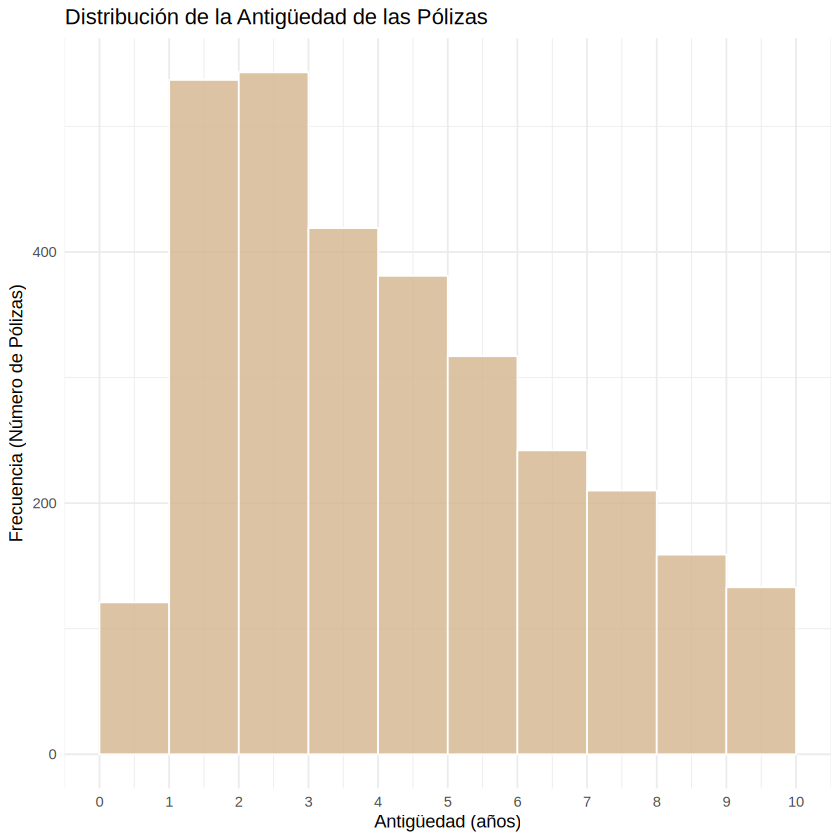

In [3]:

# Crear histograma de la variable antiguedad con cortes en enteros [0,1), [1,2), etc.
ggplot(cartera, aes(x = antiguedad)) +
  geom_histogram(binwidth = 1, boundary = 0, fill = "tan", color = "white", alpha = 0.8) +
  labs(
    title = "Distribución de la Antigüedad de las Pólizas",
    x = "Antigüedad (años)",
    y = "Frecuencia (Número de Pólizas)"
  ) +
  scale_x_continuous(breaks = 0:max(ceiling(cartera$antiguedad))) +
  theme_minimal()


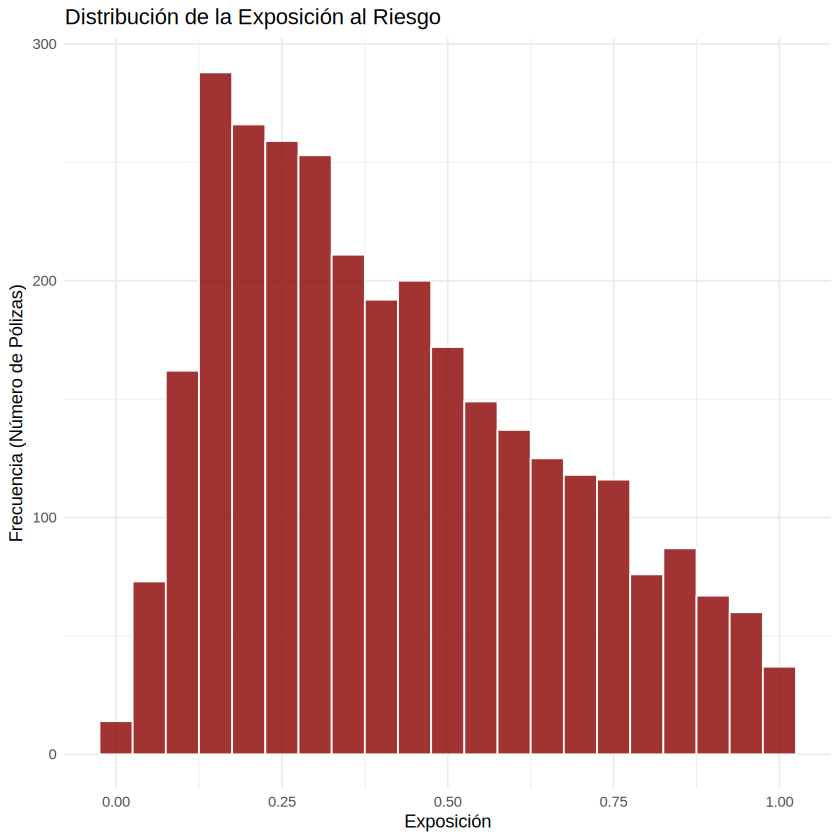

In [4]:
library(ggplot2)

# Crear histograma de la variable exposicion
ggplot(cartera, aes(x = exposicion)) +
  geom_histogram(binwidth = 0.05, fill = "darkred", color = "white", alpha = 0.8) +
  labs(
    title = "Distribución de la Exposición al Riesgo",
    x = "Exposición",
    y = "Frecuencia (Número de Pólizas)"
  ) +
  theme_minimal()


-----

# Variables y tasas observadas

- $y[i]$: Siniestros reales, ocurrentes en el cliente $i$
- $x[i]$: Exposición del cliente i. Tiempo de observación. Transformamos para expresar en años.
- $λ[i]$: Tasa de siniestros individual, de la póliza.
$$
λ[i] = y[i] : X[i]
$$

- $Λ$: Tasa global estimada.

- Siniestros esperados
$$
ŷ[i] = modelo
$$



In [5]:
#-- función de cálculo de tasas, con control de errores
tasa <- function(
        eventos,
        exposicion
        ) {
    stopifnot(
        length(eventos) == length(exposicion),
        all(!is.na(exposicion)),
        all(exposicion > 0)
        )
    eventos / exposicion
    }

id_poliza,exposicion_anual,n_siniestros,tasa_siniestros
<dbl>,<dbl>,<dbl>,<dbl>
1,1.082,1,0.9242144
2,6.687,0,0.0000000
3,5.732,4,0.6978367
4,1.397,0,0.0000000
5,1.968,0,0.0000000
6,3.159,1,0.3165559


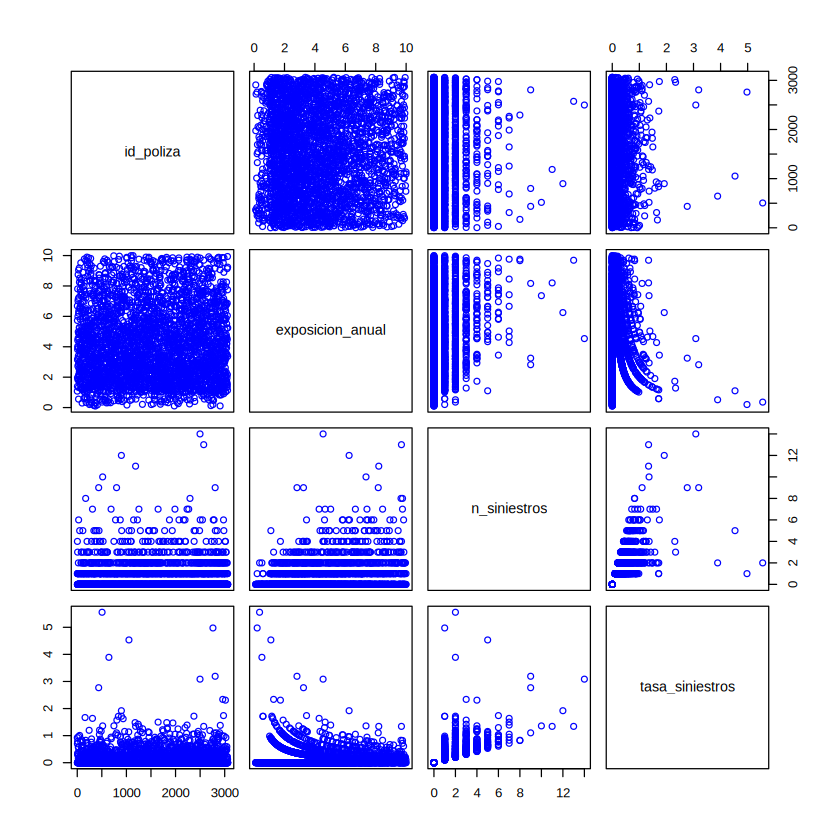

In [6]:
#-- Datos de interés
data <- cartera %>%
    mutate(
        exposicion_anual = exposicion * 10,
        tasa_siniestros  = tasa(
                n_siniestros,
                exposicion_anual)
        ) %>%
    select(
        id_poliza,
        exposicion_anual,
        n_siniestros,
        tasa_siniestros
        )

#-- Comprobación
head(data)
plot(data, col= "Blue")

In [7]:
summary(data)

   id_poliza      exposicion_anual  n_siniestros     tasa_siniestros 
 Min.   :   1.0   Min.   :0.100    Min.   : 0.0000   Min.   :0.0000  
 1st Qu.: 766.2   1st Qu.:2.194    1st Qu.: 0.0000   1st Qu.:0.0000  
 Median :1531.5   Median :3.768    Median : 0.0000   Median :0.0000  
 Mean   :1531.5   Mean   :4.207    Mean   : 0.5781   Mean   :0.1395  
 3rd Qu.:2296.8   3rd Qu.:5.934    3rd Qu.: 1.0000   3rd Qu.:0.1810  
 Max.   :3062.0   Max.   :9.996    Max.   :14.0000   Max.   :5.5556  

In [8]:
n <- sum(data$n_siniestros)
t <- sum(data$exposicion_anual)
tasa_global <- n / t
tasa_media <- mean(data$tasa_siniestros)
#-- trataría por igual la tasa de una póliza observada durante poco tiempo y la de otra observada durante muchos años
n
t
tasa_global
tasa_media

[1] 1770

[1] 12882.35

[1] 0.1373972

[1] 0.1395306

El cálculo de $Λ$ es:
$$
Λ_{\text{global}}
=
\frac{\sum[n_{[i]}]}{\sum[t_{[i]}]}
=
\frac{1770\ \text{siniestros}}
     {12882{,}354\ \text{años-póliza}}
\approx
0{,}1374\ \frac{\text{siniestros}}{\text{año-póliza}}.
$$

Un año-póliza es una póliza observada durante un año. Dos pólizas observadas durante medio año también suman un año-póliza.

Por tanto, la cartera registra aproximadamente 13,74 siniestros por cada 100 años-póliza de observación.

💡 Aquí sumamos primero y dividimos después. `mean(data$tasa_siniestros)` dará otra media: trataría por igual la tasa de una póliza observada durante poco tiempo y la de otra observada durante muchos años.

----

# Nueva hipótesis

> Las pólizas comparten una misma tasa esperada de siniestros por año.

$$
\boxed{
\text{siniestros esperados}
=
\text{años de exposición}
\times
\text{tasa global}
}
$$

Queremos predecir el número de siniestros, que sigue esta relación:
$$
ŷ_{[i]} = x_{[i]} · Λ_{\text{global}}
$$


id_poliza,Y,exposicion,err,err_sq
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.1486638,1.082,-0.8513362,0.72477329
2,0.9187754,6.687,0.9187754,0.84414824
3,0.7875610,5.732,-3.2124390,10.31976413
4,0.1919440,1.397,0.1919440,0.03684248
5,0.2703978,1.968,0.2703978,0.07311496
6,0.4340379,3.159,-0.5659621,0.32031309


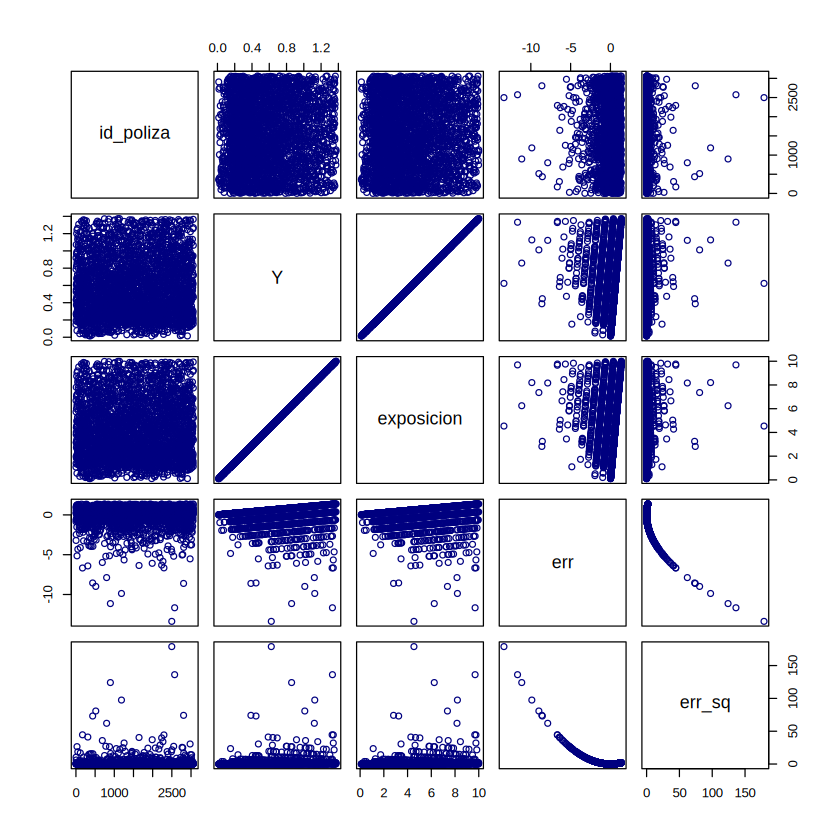

In [9]:
y_data <- data %>%
  transmute(
    id_poliza,
    Y = exposicion_anual*tasa_global,
    exposicion = exposicion_anual,
    err = Y - n_siniestros,
    err_sq = err^2
    )
head(y_data)
plot(y_data, col= "Navy")

id_poliza,lexposicion,ly,y,err,err_sq
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.07881118,-1.90606774,0.1486638,-0.8513362,0.72477329
2,1.90016534,-0.08471358,0.9187754,0.9187754,0.84414824
3,1.74606451,-0.23881441,0.7875610,-3.2124390,10.31976413
4,0.33432708,-1.65055184,0.1919440,0.1919440,0.03684248
5,0.67701780,-1.30786112,0.2703978,0.2703978,0.07311496
6,1.15025552,-0.83462340,0.4340379,-0.5659621,0.32031309


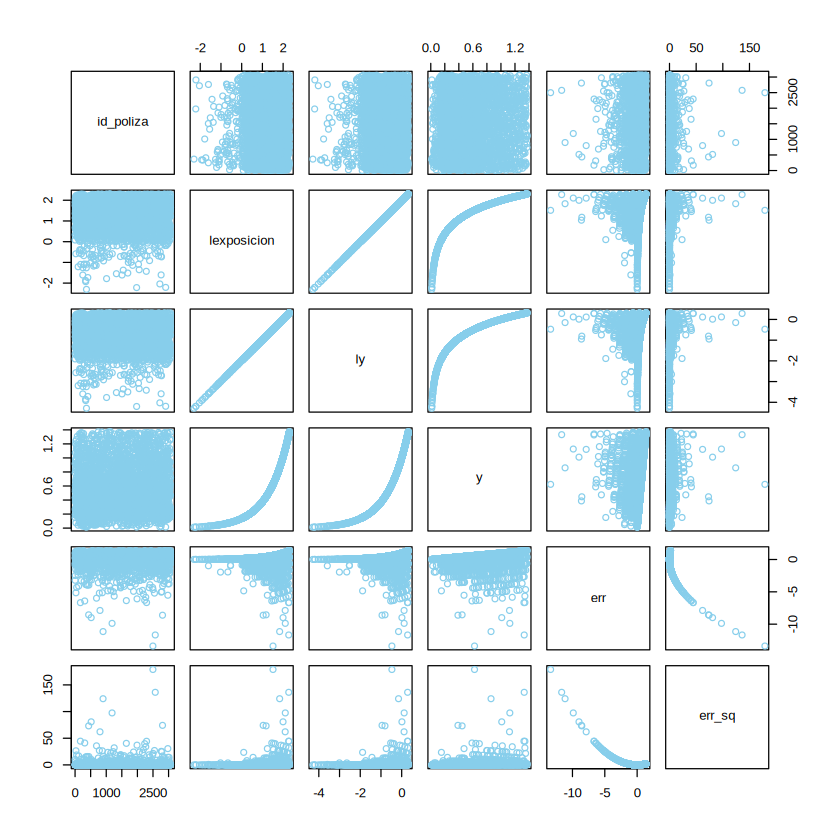

In [10]:
ly_data <- data %>%
  transmute(
    id_poliza,
    lexposicion = log(exposicion_anual),
    ly = lexposicion+log(tasa_global),
    y = exp(ly),
    err = y - n_siniestros,
    err_sq = err^2
    )
head(ly_data)
plot(ly_data, col= "skyblue")

In [11]:
sum(y_data$err_sq)

[1] 4082.408

In [12]:
sum(ly_data$err_sq)

[1] 4082.408

Para expresar de forma aditiva la regla de la media, aplicamos logaritmos.

$$
\log ŷ_{[i]} = \log x_{[i]} + \log Λ
$$


$$
β_0 = \log Λ
$$

Estamos expresando el supuesto de que, manteniendo la tasa, la media crece proporcionalmente a la exposición.

,observados,log_esperados,esperados
,<dbl>,<dbl>,<dbl>
1,1,-1.90606774,0.1486638
2,0,-0.08471358,0.9187754
3,4,-0.23881441,0.7875610
4,0,-1.65055184,0.1919440
5,0,-1.30786112,0.2703978
6,1,-0.83462340,0.4340379


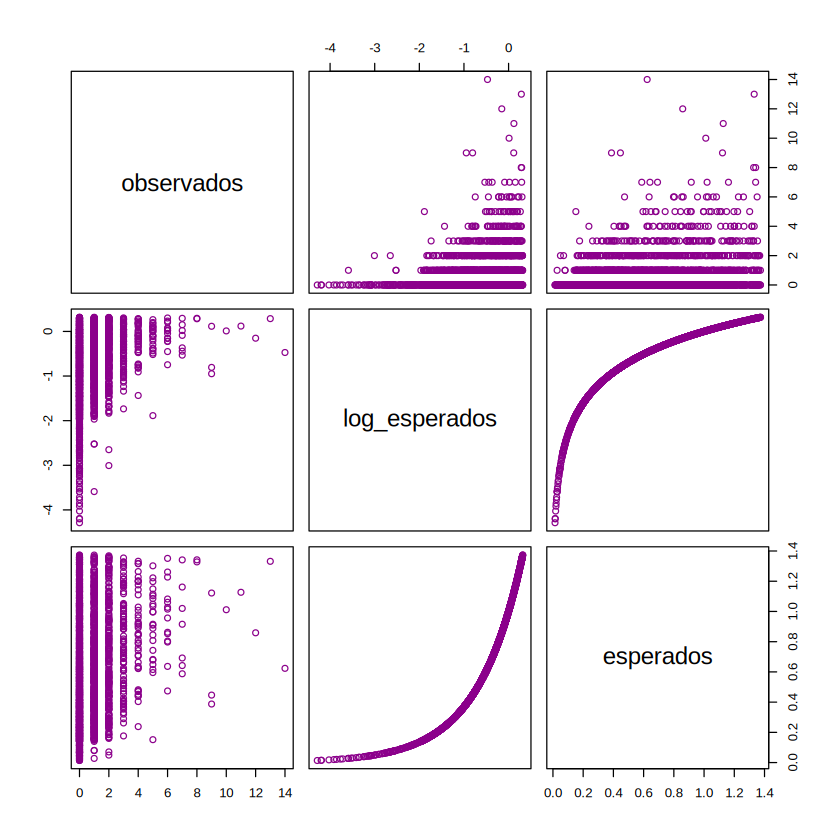

In [13]:
modelo_base <- glm(
  n_siniestros ~ 1 + offset(log(exposicion_anual)),
  family = poisson(link = "log"),
  data = data
)

log_esperados <- predict(modelo_base, type = "link")
esperados <- exp(log_esperados)

df = data.frame(
  observados = data$n_siniestros,
  log_esperados,
  esperados)

head(df)
plot(df, col="DarkMagenta")

In [14]:
exp(coef(modelo_base)[1])
tasa_global

(Intercept) 
  0.1373972

[1] 0.1373972